# Từ dữ liệu đến Macro-F1: so sánh Naive Bayes, Logistic Regression và Linear SVM

Quy trình: đọc validation → nạp pipeline đã train → dự đoán → confusion matrix → TP/FP/FN → F1 từng lớp → Macro-F1 → biểu đồ → quyết định chọn pipeline.

Chạy bằng kernel `.venv` của student_feedback (pandas, NumPy, matplotlib, scikit-learn, joblib). Notebook không train lại. Đánh giá riêng cảm xúc (3 lớp) và chủ đề (4 lớp), không dùng test để chọn mô hình.

**Phạm vi so sánh:** NB và LR dùng TF-IDF baseline trên train gốc; SVM đã cải tiến đặc trưng/tăng cường dữ liệu. Đây là so sánh các pipeline đã lưu, không phải thí nghiệm cô lập tác động thuật toán. Validation đã dùng trong thí nghiệm trước, nên kết quả này phục vụ tái đánh giá/báo cáo, không phải kiểm định độc lập. Chỉ kết luận chọn SVM khi điểm đo thực tế ủng hộ.


In [1]:
from pathlib import Path
import sys, json, hashlib
import numpy as np
import pandas as pd
import joblib
import matplotlib
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    matplotlib.use('Agg')
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, f1_score
candidates = [p/s for p in [Path.cwd(), *Path.cwd().parents]
              for s in ('', 'student_feedback', 'student-feedback-ai/student_feedback')]
ROOT = next((p for p in candidates if (p/'data/raw/train/sents.txt').is_file() and (p/'src/feedback_ai').is_dir()), None)
if ROOT is None:
    raise FileNotFoundError('Mở notebook từ workspace hoặc student_feedback.')
sys.path.insert(0, str(ROOT/'src'))
from feedback_ai.data.loader import load_split
from feedback_ai.common.labels import SENTIMENT_LABELS, TOPIC_LABELS
LABELS = {'sentiment': list(SENTIMENT_LABELS), 'topic': list(TOPIC_LABELS)}
MODELS = {'Naive Bayes': ('multinomial_naive_bayes','nb_'),
          'Logistic Regression': ('logistic_regression','logistic_regression_'),
          'Linear SVM': ('linear_svm','')}
BASE = ROOT/'artifacts/serving/ct4/research-selected'
validation = load_split(ROOT/'data/raw', 'validation')
print('Python:', sys.executable)
print('Validation:', len(validation), 'câu')
print(validation.head().to_string(index=False))
for task in LABELS:
    print(task, validation[task].value_counts().to_dict())


Python: D:\N.ThanhNhan\Project_AI\student-feedback-ai\student-feedback-ai\student_feedback\.venv\Scripts\python.exe
Validation: 1583 câu
               id                                                                                                                                                      text sentiment      topic      split
validation:000001                                                                                                                                  giáo trình chưa cụ thể .  negative curriculum validation
validation:000002                                                                                                                                          giảng buồn ngủ .  negative   lecturer validation
validation:000003                                                                                                                            giáo viên vui tính , tận tâm .  positive   lecturer validation
validation:000004 giảng viên nên giao bài tập n

## 1. Từ văn bản đến nhãn dự đoán

Mỗi pipeline chứa bước biểu diễn văn bản và bộ phân loại đã học. Văn bản validation được biến đổi bằng đặc trưng đã fit trước đó, rồi gọi `predict`. Không fit lại trên validation. Nhãn thật chỉ dùng tính điểm.

Dự đoán ở đây là đầu ra trực tiếp của pipeline, chưa áp dụng cơ chế từ chối trả lời/ngưỡng của web. Kiểm tra SHA-256 trước khi nạp artifact tin cậy của dự án.


In [2]:
predictions = {}
for task in LABELS:
    for name, (folder, prefix) in MODELS.items():
        directory = BASE/folder
        artifact = directory/f'{task}_{prefix}pipeline.joblib'
        metadata = json.loads((directory/f'{task}_{prefix}metadata.json').read_text(encoding='utf-8'))
        if hashlib.sha256(artifact.read_bytes()).hexdigest() != metadata['artifact_sha256']:
            raise ValueError(f'Artifact không khớp metadata: {artifact}')
        model = joblib.load(artifact)
        predicted = np.asarray(model.predict(validation.text.tolist()), dtype=str)
        assert len(predicted)==len(validation) and set(predicted).issubset(LABELS[task])
        predictions[task,name] = predicted
        print('Đã dự đoán:', task, name, '|', artifact.name)
example = validation[['text','sentiment']].head(8).copy()
for name in MODELS:
    example[name] = predictions['sentiment',name][:len(example)]
print('Đối chiếu 8 câu đầu, không chọn lọc:')
print(example.to_string(index=False))


Đã dự đoán: sentiment Naive Bayes | sentiment_nb_pipeline.joblib
Đã dự đoán: sentiment Logistic Regression | sentiment_logistic_regression_pipeline.joblib
Đã dự đoán: sentiment Linear SVM | sentiment_pipeline.joblib
Đã dự đoán: topic Naive Bayes | topic_nb_pipeline.joblib
Đã dự đoán: topic Logistic Regression | topic_logistic_regression_pipeline.joblib
Đã dự đoán: topic Linear SVM | topic_pipeline.joblib
Đối chiếu 8 câu đầu, không chọn lọc:
                                                                                                                                                     text sentiment Naive Bayes Logistic Regression Linear SVM
                                                                                                                                 giáo trình chưa cụ thể .  negative    negative            negative   negative
                                                                                                                                         giản

## 2. Tính từng bước từ confusion matrix

**Hàng là nhãn thật, cột là nhãn dự đoán.** Với mỗi lớp k:

- TP: phần tử đường chéo của lớp k (dự đoán đúng lớp).
- FP: tổng cột k trừ TP (đoán nhầm lớp khác thành k).
- FN: tổng hàng k trừ TP (bỏ sót lớp k).
- Precision = TP / (TP + FP).
- Recall = TP / (TP + FN).
- **F1 = 2 × TP / (2 × TP + FP + FN)**.
- **Macro-F1 = tổng F1 của các lớp / số lớp**.

Mẫu số bằng 0 thì quy ước chỉ số bằng 0. Macro-F1 là trung bình F1 từng lớp, không phải F1 tính từ trung bình Precision/Recall. Cảm xúc chia cho 3, chủ đề chia cho 4. Mỗi lớp được coi trọng như nhau nên phù hợp khi nhãn trung lập và một số chủ đề ít mẫu. Accuracy = tổng đường chéo / tổng số câu, dùng bổ trợ.


In [3]:
def calculate(truth, predicted, labels):
    cm = confusion_matrix(truth, predicted, labels=labels)
    tp = np.diag(cm).astype(float)
    fp, fn = cm.sum(axis=0)-tp, cm.sum(axis=1)-tp
    def div(a,b):
        return np.divide(a,b,out=np.zeros_like(a,dtype=float),where=b!=0)
    precision, recall, f1 = div(tp,tp+fp), div(tp,tp+fn), div(2*tp,2*tp+fp+fn)
    table = pd.DataFrame({'label':labels,'TP':tp.astype(int),'FP':fp.astype(int),'FN':fn.astype(int),
                          'support':cm.sum(axis=1),'precision':precision,'recall':recall,'f1':f1})
    macro = float(f1.mean())
    assert np.isclose(macro, f1_score(truth,predicted,labels=labels,average='macro',zero_division=0))
    return cm,table,macro,float(tp.sum()/cm.sum())
rows, detail_rows, matrices = [], [], {}
for task,labels in LABELS.items():
    for name in MODELS:
        cm,detail,macro,accuracy = calculate(validation[task].tolist(),predictions[task,name],labels)
        matrices[task,name] = cm
        detail_rows.append(detail.assign(task=task,model=name))
        rows.append({'task':task,'model':name,'macro_f1':macro,'accuracy':accuracy})
        print(f'\n{task} — {name}')
        print(detail.round(4).to_string(index=False))
        print('Macro-F1 = ('+' + '.join(f'{v:.6f}' for v in detail.f1)+f') / {len(labels)} = {macro:.6f}')
summary = pd.DataFrame(rows)
details = pd.concat(detail_rows,ignore_index=True)
print('\nTổng hợp (thang 0–1):\n',summary.round(4).to_string(index=False))



sentiment — Naive Bayes
   label  TP  FP  FN  support  precision  recall     f1
negative 662 135  43      705     0.8306  0.9390 0.8815
 neutral   0   0  73       73     0.0000  0.0000 0.0000
positive 720  66  85      805     0.9160  0.8944 0.9051
Macro-F1 = (0.881491 + 0.000000 + 0.905091) / 3 = 0.595527

sentiment — Logistic Regression
   label  TP  FP  FN  support  precision  recall     f1
negative 673  88  32      705     0.8844  0.9546 0.9181
 neutral   9   2  64       73     0.8182  0.1233 0.2143
positive 755  56  50      805     0.9309  0.9379 0.9344
Macro-F1 = (0.918145 + 0.214286 + 0.934406) / 3 = 0.688945

sentiment — Linear SVM
   label  TP  FP  FN  support  precision  recall     f1
negative 655  57  50      705     0.9199  0.9291 0.9245
 neutral  33  17  40       73     0.6600  0.4521 0.5366
positive 757  64  48      805     0.9220  0.9404 0.9311
Macro-F1 = (0.924488 + 0.536585 + 0.931119) / 3 = 0.797398

topic — Naive Bayes
     label   TP  FP  FN  support  precision  rec

## 3. Biểu đồ Macro-F1 và F1 từng lớp

Cột đứng giúp so sánh ba giá trị, trục 0–100% tránh phóng đại chênh lệch. Cột nhóm F1 từng lớp giải thích chất lượng lớp thiểu số. Vẽ riêng hai bài toán; màu xanh lá luôn biểu diễn SVM, không mặc định thắng cuộc.


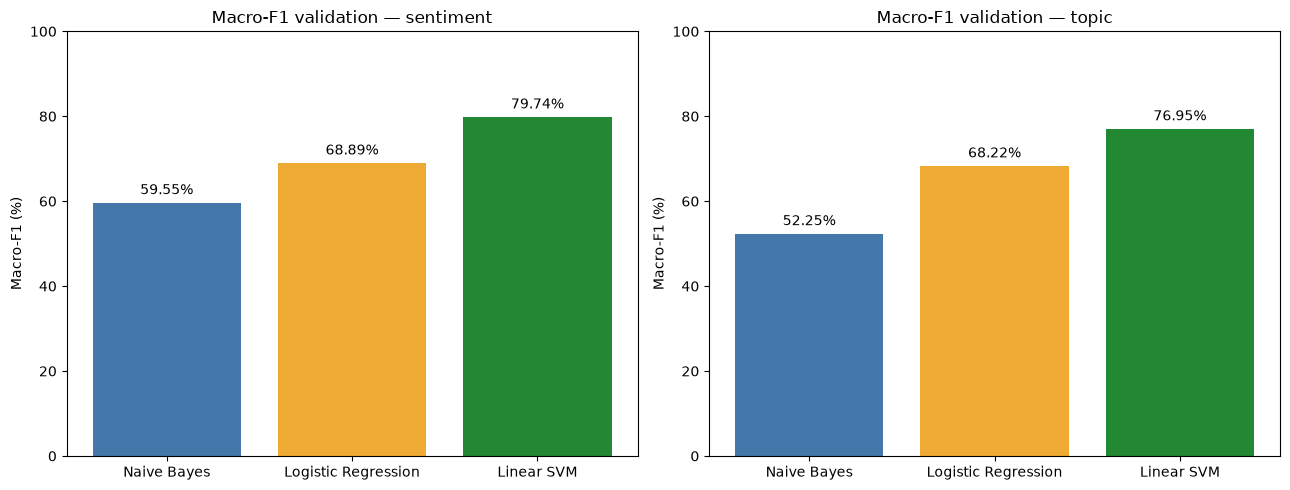

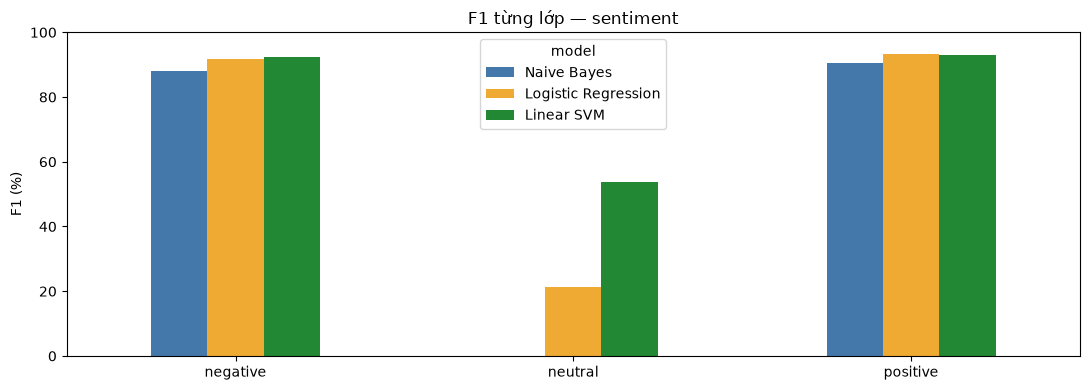

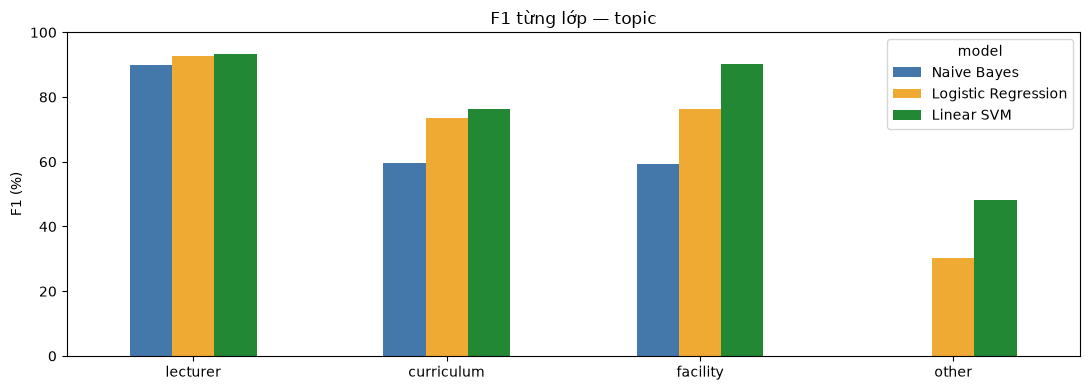

In [4]:
colors = ['#4477AA','#EEAA33','#228833']
fig,axes = plt.subplots(1,2,figsize=(13,5))
for ax,task in zip(axes,LABELS):
    values = summary[summary.task.eq(task)].set_index('model').reindex(list(MODELS)).macro_f1*100
    bars = ax.bar(list(MODELS),values,color=colors)
    ax.bar_label(bars,labels=[f'{v:.2f}%' for v in values],padding=4)
    ax.set(title=f'Macro-F1 validation — {task}',ylabel='Macro-F1 (%)',ylim=(0,100))
fig.tight_layout()
plt.show()
plt.close(fig)
for task,labels in LABELS.items():
    table = details[details.task.eq(task)].pivot(index='label',columns='model',values='f1').reindex(index=labels,columns=list(MODELS))
    ax = (table*100).plot.bar(figsize=(11,4),color=colors,rot=0)
    ax.set(title=f'F1 từng lớp — {task}',ylabel='F1 (%)',ylim=(0,100),xlabel='')
    ax.figure.tight_layout()
    plt.show()
    plt.close(ax.figure)


## 4. Confusion matrix của ba mô hình

Số trên từng ô là số câu. Các mô hình trong cùng bài toán dùng chung thang màu; hàng là thực tế, cột là dự đoán. Các ô ngoài đường chéo chỉ ra cặp nhãn còn nhầm lẫn.


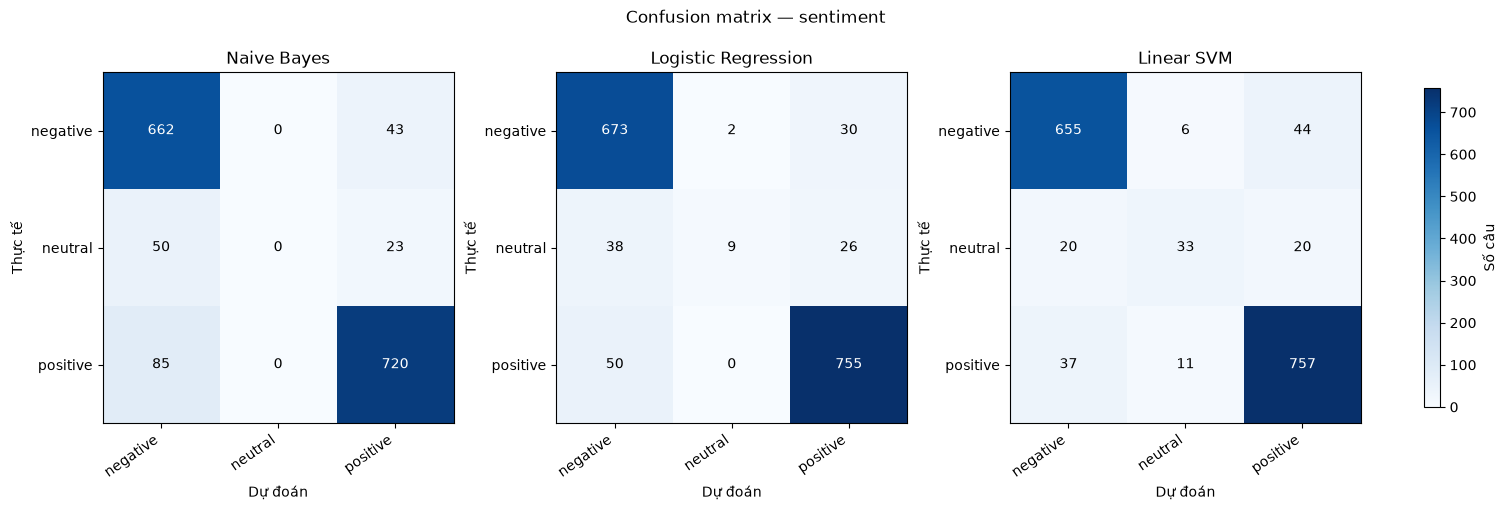

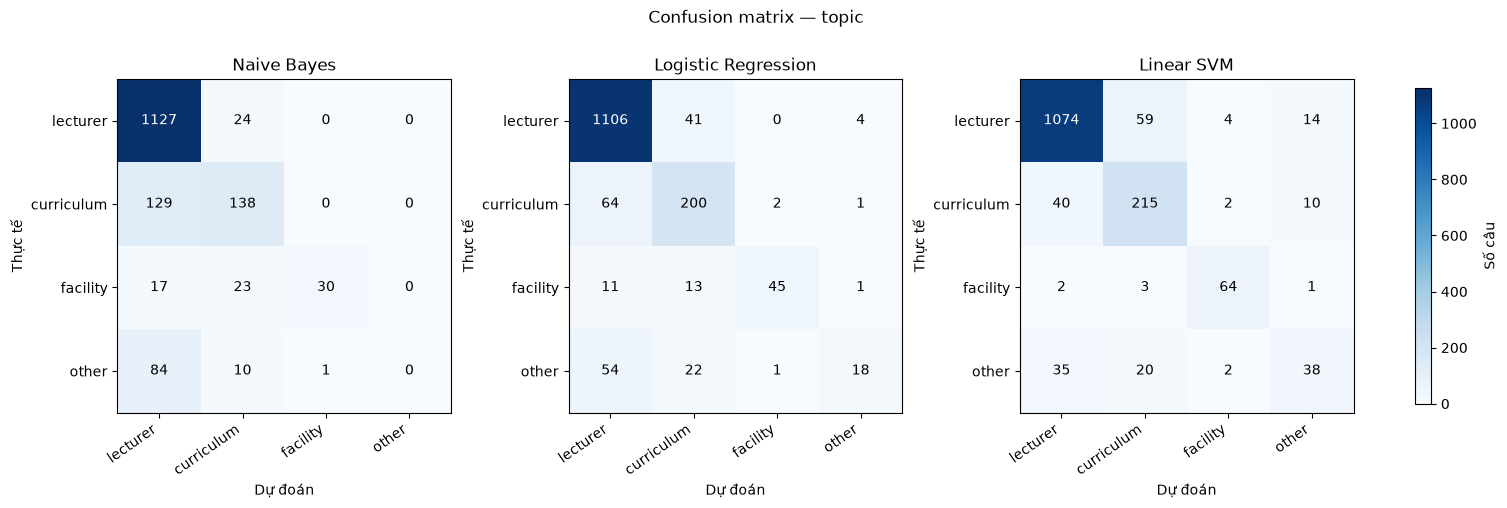

In [5]:
for task,labels in LABELS.items():
    fig,axes = plt.subplots(1,3,figsize=(15,5),layout='constrained')
    maximum = max(matrices[task,name].max() for name in MODELS)
    for ax,name in zip(axes,MODELS):
        cm = matrices[task,name]
        im = ax.imshow(cm,cmap='Blues',vmin=0,vmax=maximum)
        ax.set_xticks(range(len(labels)),labels,rotation=35,ha='right')
        ax.set_yticks(range(len(labels)),labels)
        ax.set(title=name,xlabel='Dự đoán',ylabel='Thực tế')
        for i in range(len(labels)):
            for j in range(len(labels)):
                ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>maximum*.55 else 'black')
    fig.suptitle(f'Confusion matrix — {task}')
    fig.colorbar(im,ax=list(axes),shrink=.75,label='Số câu')
    plt.show()
    plt.close(fig)


## 5. Kết luận lựa chọn theo kết quả thực tế

Ưu tiên Macro-F1 trên validation. Cell sau chỉ kết luận chọn SVM khi SVM đứng đầu duy nhất; nếu hòa trong sai số 1e-6 thì cần xem accuracy, độ trễ và độ ổn định. Kết quả không tự động thay đổi mô hình web.


In [6]:
for task in LABELS:
    scores = summary[summary.task.eq(task)].set_index('model')
    best = scores.macro_f1.max()
    winners = scores.index[np.isclose(scores.macro_f1,best,atol=1e-6,rtol=0)].tolist()
    print(f'\nKẾT LUẬN {task.upper()}:')
    print(scores.round(4).to_string())
    if winners == ['Linear SVM']:
        print('Chọn pipeline Linear SVM hiện tại: Macro-F1 validation cao nhất trong ba pipeline đã đánh giá.')
        for name in list(MODELS)[:2]:
            delta = (scores.loc['Linear SVM','macro_f1']-scores.loc[name,'macro_f1'])*100
            print(f'Cao hơn {name}: {delta:.2f} điểm phần trăm Macro-F1.')
    else:
        print('Mô hình đứng đầu:', ', '.join(winners), '— chưa đủ căn cứ chốt duy nhất SVM.')
    part = details[details.task.eq(task) & details.model.eq('Linear SVM')]
    weakest = part.loc[part.f1.idxmin()]
    print(f'Lớp SVM yếu nhất theo F1: {weakest.label}; F1={weakest.f1:.4f}; support={weakest.support}.')
print('\nGiới hạn: pipeline khác cấu hình/nguồn train; chưa chứng minh ý nghĩa thống kê của chênh lệch. '
      'Đánh giá test sau khi chốt cấu hình để đo khả năng tổng quát hóa.')



KẾT LUẬN SENTIMENT:
                          task  macro_f1  accuracy
model                                             
Naive Bayes          sentiment    0.5955    0.8730
Logistic Regression  sentiment    0.6889    0.9078
Linear SVM           sentiment    0.7974    0.9128
Chọn pipeline Linear SVM hiện tại: Macro-F1 validation cao nhất trong ba pipeline đã đánh giá.
Cao hơn Naive Bayes: 20.19 điểm phần trăm Macro-F1.
Cao hơn Logistic Regression: 10.85 điểm phần trăm Macro-F1.
Lớp SVM yếu nhất theo F1: neutral; F1=0.5366; support=73.

KẾT LUẬN TOPIC:
                      task  macro_f1  accuracy
model                                         
Naive Bayes          topic    0.5225    0.8181
Logistic Regression  topic    0.6822    0.8648
Linear SVM           topic    0.7695    0.8787
Chọn pipeline Linear SVM hiện tại: Macro-F1 validation cao nhất trong ba pipeline đã đánh giá.
Cao hơn Naive Bayes: 24.69 điểm phần trăm Macro-F1.
Cao hơn Logistic Regression: 8.72 điểm phần trăm Macro-F1.
L